Carregamento dos dados. Dataset do Open Food Facts. Pegamos apenas 300 mil linhas

(Rodar ele pode causar alguns warnings mas nada grave)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

!gdown  1bIQxBpjnVyBG8LXGUXQ1NC5eLPESiedT

df = pd.read_csv('openfoodfacts_300k.csv', low_memory=False)

display(df.head())

Downloading...
From (original): https://drive.google.com/uc?id=1bIQxBpjnVyBG8LXGUXQ1NC5eLPESiedT
From (redirected): https://drive.google.com/uc?id=1bIQxBpjnVyBG8LXGUXQ1NC5eLPESiedT&confirm=t&uuid=e54164da-e3b8-4ed2-8e02-49a5da1bbca3
To: /content/openfoodfacts_300k.csv
100% 848M/848M [00:04<00:00, 188MB/s]


,code,url,creator,created_t,created_datetime,last_modified_t,last_modified_datetime,last_modified_by,last_updated_t,last_updated_datetime,...,choline_100g,phylloquinone_100g,beta-glucan_100g,inositol_100g,carnitine_100g,sulphate_100g,nitrate_100g,acidity_100g,carbohydrates-total_100g,water_100g
0,54,http://world-en.openfoodfacts.org/product/0000...,kiliweb,1582569031,2020-02-24T18:30:31Z,1733085204,2024-12-01T20:33:24Z,NaN,1.740205e+09,2025-02-22T06:23:42Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,63,http://world-en.openfoodfacts.org/product/0000...,kiliweb,1673620307,2023-01-13T14:31:47Z,1750061386,2025-06-16T08:09:46Z,bodysupport,1.750061e+09,2025-06-16T08:09:46Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,114,http://world-en.openfoodfacts.org/product/0000...,kiliweb,1580066482,2020-01-26T19:21:22Z,1751035658,2025-06-27T14:47:38Z,teolemon,1.751036e+09,2025-06-27T14:47:38Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,431,http://world-en.openfoodfacts.org/product/0000...,kiliweb,1714301712,2024-04-28T10:55:12Z,1714301721,2024-04-28T10:55:21Z,kiliweb,1.714302e+09,2024-04-28T10:55:21Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,105,http://world-en.openfoodfacts.org/product/0000...,kiliweb,1572117743,2019-10-26T19:22:23Z,1738073570,2025-01-28T14:12:50Z,NaN,1.743653e+09,2025-04-03T04:11:36Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Para a preparacao dos dados, escolhemos colunas para servir como indentificadores. Jutamos essas com colunas que teriam informacoes nutricionais e chegamos num dataset mais limpo.

Descartamos linhas com produtos sem nome ou categoria.

Removemos colunas nutricionais com pouco preenchimento e vitaminas para simplificar.

Assumimos NaN como 0g.

In [ ]:

#colunas de identificacao
colunas_identificacao = ['product_name', 'brands', 'pnns_groups_1']

#colunas nutricionais
colunas_nutricionais_todas = [col for col in df.columns if col.endswith('_100g')]

#dataset mais limpo
df_trabalho = df[colunas_identificacao + colunas_nutricionais_todas].copy()

#removendo linhas sem nome ou sem categoria
df_trabalho = df_trabalho.dropna(subset=['product_name', 'pnns_groups_1'])
df_trabalho = df_trabalho[df_trabalho['pnns_groups_1'] != 'unknown']

#removendo colunas nutricionais com muitos zeros para simplificar
limite_minimo = len(df_trabalho) * 0.15
colunas_nutricionais_validas = [col for col in colunas_nutricionais_todas if df_trabalho[col].count() > limite_minimo]

colunas_finais = colunas_identificacao + colunas_nutricionais_validas
df_limpo = df_trabalho[colunas_finais].copy()

#transformando NaN em zeros.
df_limpo[colunas_nutricionais_validas] = df_limpo[colunas_nutricionais_validas].fillna(0)

print("CONCLUIDO")
print(f"linhas prontas: {df_limpo.shape[0]}")
print(f"numero de colunas: {df_limpo.shape[1]}")
print("\ncategorias finais disponiveis:")
print(df_limpo['pnns_groups_1'].value_counts())

print("\nprimeiras linhas:")
display(df_limpo.head())

CONCLUIDO
linhas prontas: 95125
numero de colunas: 16

categorias finais disponiveis:
pnns_groups_1
Sugary snacks              21648
Cereals and potatoes       13626
Beverages                  12462
Fat and sauces             11466
Milk and dairy products     9350
Fish Meat Eggs              7723
Fruits and vegetables       7691
Composite foods             7111
Salty snacks                3625
Alcoholic beverages          366
Baby foods                    57
Name: count, dtype: int64

primeiras linhas:


,product_name,brands,pnns_groups_1,energy-kj_100g,energy-kcal_100g,energy_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,added-sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,fruits-vegetables-legumes_100g
4,Paleta gran reserva - Sierra nevada-,AdvoCare,Beverages,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
12,granola Bio le Chocolaté,Mg ricarica,Fruits and vegetables,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
14,xytitol pastilles,xylimgxyling,Composite foods,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
15,xxx,xxx,Beverages,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18,Powdered peanut butter,Pbfit,Composite foods,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Continuando o tratamento dos dados, percebemos que ainda haviam varios dados com as tabelas nutricionais vazias.

Alem disso, tambem removemos dados que pareciam spam, como "xxx".

In [ ]:
#remove produtos sem nada preenchido
df_limpo['soma_nutrientes'] = df_limpo[colunas_nutricionais_validas].sum(axis=1)
df_limpo = df_limpo[df_limpo['soma_nutrientes'] > 0]
df_limpo = df_limpo.drop(columns=['soma_nutrientes'])

#removendo spam e nomes curtos
df_limpo = df_limpo[df_limpo['product_name'].astype(str).str.len() >= 4]
df_limpo = df_limpo[df_limpo['brands'].astype(str).str.len() >= 3]

print("CONLUIDO")
print(f"Linhas restante: {df_limpo.shape[0]}")
display(df_limpo.head(10))

CONLUIDO
Linhas restante: 21842


,product_name,brands,pnns_groups_1,energy-kj_100g,energy-kcal_100g,energy_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,added-sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,fruits-vegetables-legumes_100g
875,Donut Milka,Milka,Sugary snacks,1928.500000,465.0,1928.500000,28.000000,13.80,46.5,18.0,0.0,0.0,6.000000,0.649,0.2596,0.000000
890,Véritable pâte à tartiner noisettes chocolat noir,Bovetti,Sugary snacks,2524.000000,617.0,2524.000000,48.000000,10.00,36.0,32.0,0.0,0.0,8.000000,0.010,0.0040,0.000000
935,Le Petit Bridé,Teyssier,Fish Meat Eggs,0.000000,0.0,0.000000,0.000000,0.00,0.0,0.0,12.5,0.0,0.000000,0.000,0.0000,1.562500
946,Chorizo,Teyssier,Fish Meat Eggs,1357.900028,434.0,1357.900028,36.700001,12.70,0.0,0.0,0.0,0.0,0.000000,0.000,0.0000,0.000000
947,Chorizo,NaN,Fish Meat Eggs,1771.899957,428.0,1771.899957,35.299999,12.20,5.1,4.1,0.0,0.0,22.299999,3.900,1.5600,0.000000
954,Poutargue de mulet,NaN,Fish Meat Eggs,1569.200000,377.0,1569.200000,22.700000,12.29,2.4,0.2,0.0,0.0,40.500000,3.850,1.5400,0.000000
955,Coca cola,Coca-Cola,Beverages,1179.200000,42.0,1179.200000,27.000000,0.00,10.6,1.0,0.0,0.0,0.000000,0.000,0.0000,0.000000
959,Saucisson sec au piment d'espelette,NaN,Fish Meat Eggs,1657.100000,400.0,1657.100000,33.300000,11.50,0.9,0.7,0.0,0.0,24.100000,4.700,1.8800,0.000000
968,Chorizo,NaN,Fish Meat Eggs,1798.200000,434.0,1798.200000,36.700000,12.70,5.0,4.0,0.0,0.0,20.900000,3.800,1.5200,0.000000
1000,Riovida Burst,4life,Beverages,0.000000,0.0,0.000000,0.000000,0.00,0.0,0.0,0.0,0.0,0.000000,0.000,0.0000,97.851562


Por fim, limpamos a base de dados ainda mais removendo entradas duplicadas.

Removemos tambem colunas redudantes.

Para removermos discrepancias, calculamos um valor teorico de calorias com base nos nutrientes. Se esse valor nao bater com o que temos, removemos dos dados.

Removemos tambem possiveis outliers de dados de nutrientes acima de 100g.

Por fim, removemos linhas com menos de 3 nutrientes preenchidos (provaveis spam).

In [ ]:
#removendo entradas duplicadas
df_limpo = df_limpo.drop_duplicates(subset=['product_name', 'brands'], keep='first')

#removendo colunas redundantes
colunas_para_remover = ['energy-kj_100g', 'energy_100g', 'added_sugars_100g']
colunas_remover_existentes = [col for col in colunas_para_remover if col in df_limpo.columns]
df_limpo = df_limpo.drop(columns=colunas_remover_existentes)

colunas_nutricionais_validas = [col for col in df_limpo.columns if col.endswith('_100g')]

#calculo teorico de calorias para ver discrepancias nos dados
calorias_teoricas = (df_limpo['carbohydrates_100g'] * 4) + \
                    (df_limpo['proteins_100g'] * 4) + \
                    (df_limpo['fat_100g'] * 9)

#caso as calorias nao batam com a quantidade de nutrientes
fraude_calorica = (df_limpo['energy-kcal_100g'] == 0) & (calorias_teoricas > 10)

#caso esteja tudo certo, mantemos
df_limpo = df_limpo[~fraude_calorica]

#checagem de mais de 100g
colunas_em_gramas = [col for col in colunas_nutricionais_validas if 'energy' not in col]
for col in colunas_em_gramas:
    df_limpo = df_limpo[df_limpo[col] <= 100]

#para energia fazer sentido
if 'energy-kcal_100g' in df_limpo.columns:
    df_limpo = df_limpo[df_limpo['energy-kcal_100g'] <= 900]

#pelo menos 3 nutrientes preenchidos
max_zeros_permitidos = len(colunas_nutricionais_validas) - 3
df_limpo['contagem_zeros'] = (df_limpo[colunas_nutricionais_validas] == 0).sum(axis=1)
df_limpo = df_limpo[df_limpo['contagem_zeros'] <= max_zeros_permitidos]

df_limpo = df_limpo.drop(columns=['contagem_zeros'])

print("CONCLUIDO")
print(f"linhas restantes: {df_limpo.shape[0]}")
print(f"total de nutrientes mantidos: {len(colunas_nutricionais_validas)}")
display(df_limpo.head(10))

CONCLUIDO
linhas restantes: 19515
total de nutrientes mantidos: 11


,product_name,brands,pnns_groups_1,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,added-sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,fruits-vegetables-legumes_100g,Cluster_KMeans
875,Donut Milka,Milka,Sugary snacks,465.000000,28.000000,13.80,46.500000,18.000000,0.00,0.000000,6.000000,0.649,0.2596,0.000000,0
890,Véritable pâte à tartiner noisettes chocolat noir,Bovetti,Sugary snacks,617.000000,48.000000,10.00,36.000000,32.000000,0.00,0.000000,8.000000,0.010,0.0040,0.000000,0
946,Chorizo,Teyssier,Fish Meat Eggs,434.000000,36.700001,12.70,0.000000,0.000000,0.00,0.000000,0.000000,0.000,0.0000,0.000000,0
947,Chorizo,NaN,Fish Meat Eggs,428.000000,35.299999,12.20,5.100000,4.100000,0.00,0.000000,22.299999,3.900,1.5600,0.000000,0
954,Poutargue de mulet,NaN,Fish Meat Eggs,377.000000,22.700000,12.29,2.400000,0.200000,0.00,0.000000,40.500000,3.850,1.5400,0.000000,0
955,Coca cola,Coca-Cola,Beverages,42.000000,27.000000,0.00,10.600000,1.000000,0.00,0.000000,0.000000,0.000,0.0000,0.000000,0
959,Saucisson sec au piment d'espelette,NaN,Fish Meat Eggs,400.000000,33.300000,11.50,0.900000,0.700000,0.00,0.000000,24.100000,4.700,1.8800,0.000000,0
1019,greek yogurt,Chobani,Milk and dairy products,86.666667,1.666667,1.00,10.666667,9.333333,0.00,0.666667,7.333333,0.000,0.0000,0.000000,0
1080,boisson à l'aloe vera,Herbalife,Beverages,12.000000,0.000000,0.00,3.000000,0.000000,0.00,0.000000,0.000000,0.100,0.0400,0.683594,0
1113,Purée de pommes de terre,Dosen Bistro,Cereals and potatoes,106.520000,5.640000,3.39,11.670000,1.640000,0.15,0.000000,2.270000,0.300,0.1200,0.000000,0


Normalizacao e PCA

Usamos a normalizacao pois ela e essencial para equalizar a escala das variaveis, evitando que atributos de maior magnitude dominem o calculo das distancias entre os dados

Na sequencia, a aplicação do PCA reduz a dimensionalidade do conjunto, eliminando redundancias entre atributos correlacionados sem perder a variabilidade original.

Essa combinação garante que todos os nutrientes tenham o mesmo peso, tornando os resultados mais precisos, interpretaveis e computacionalmente eficientes.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd

#separando dados numericos
X = df_limpo[colunas_nutricionais_validas].copy()

#guardando categorias
y_categorias = df_limpo['pnns_groups_1'].copy()

#normalizacao
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X)

#PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_escalado)

df_pca = pd.DataFrame(data=X_pca, columns=['Componente 1', 'Componente 2'])
df_pca['Categoria_Real'] = y_categorias.reset_index(drop=True)

print("normalizacao e PCA concluidos")
print(f"tamanho do X_escalado: {X_escalado.shape}")

normalizacao e PCA concluidos
tamanho do X_escalado: (19515, 11)


Ajuste de parametros para o K-Means

Calculando o K-Means para diferentes valores de K. Isso pode levar alguns segundos...


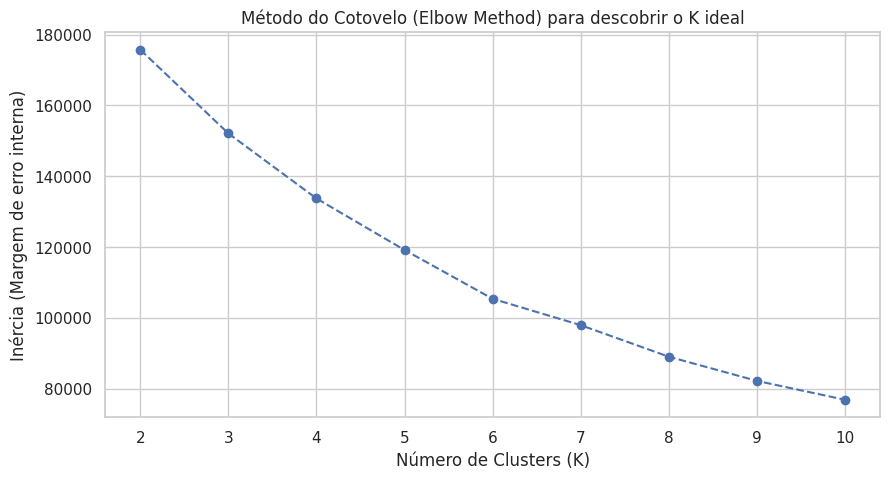

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

valores_k = range(2, 11)
inercia = []

print("Calculando o K-Means para diferentes valores de K. Isso pode levar alguns segundos...")

for k in valores_k:
    kmeans_teste = KMeans(n_clusters=k, random_state=42, n_init=10)

    kmeans_teste.fit(X_escalado)

    inercia.append(kmeans_teste.inertia_)

#geracao do grafico
plt.figure(figsize=(10, 5))
plt.plot(valores_k, inercia, marker='o', linestyle='--', color='b')
plt.title('Método do Cotovelo (Elbow Method) para descobrir o K ideal')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Inércia (Margem de erro interna)')
plt.xticks(valores_k)
plt.grid(True)
plt.show()

Aplicacao do K-Means, com o K escolhido sendo 6 apos o metodo do cotovelo.

Escolhemos o K-Means pois ele segmenta os dados com base em centroides, sendo eficiente para identificar perfis nutricionais tipicos.

Aplicando o K-Means com 6 clusters...


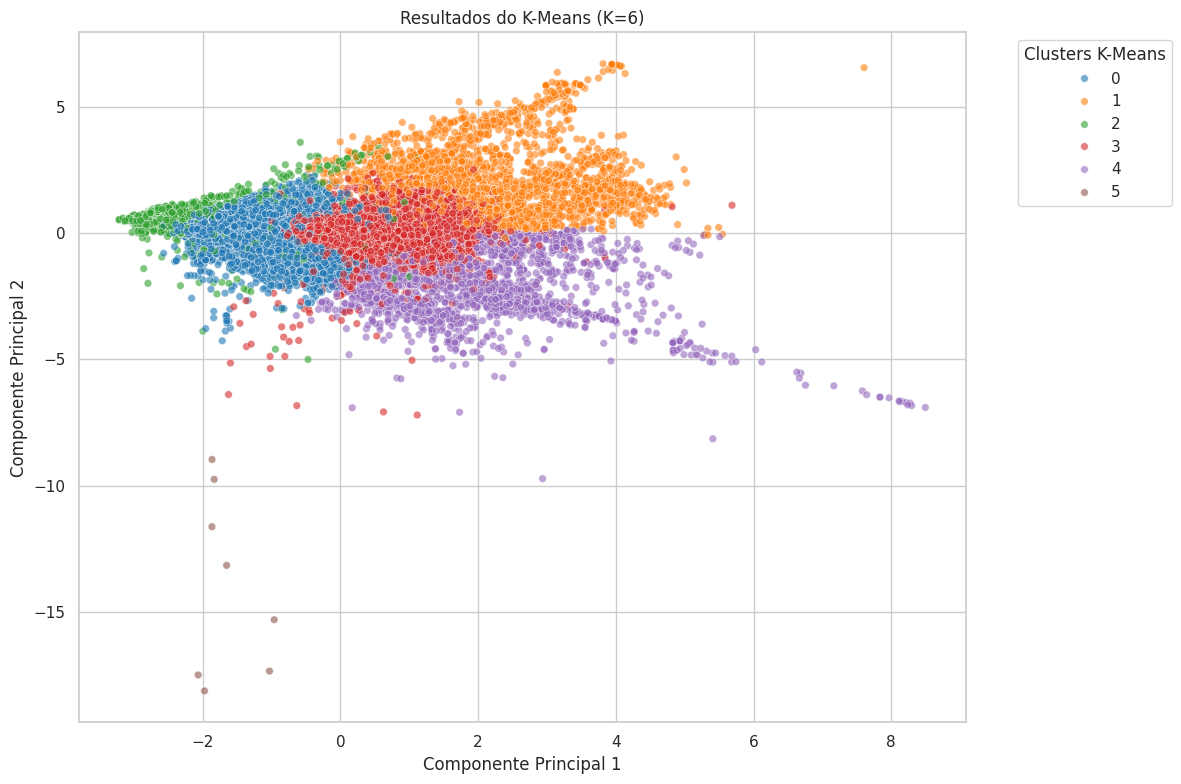


ANALISE

--- Cluster 0 ---
pnns_groups_1
Milk and dairy products    2169
Fish Meat Eggs             1119
Composite foods            1033
Name: count, dtype: int64

--- Cluster 1 ---
pnns_groups_1
Sugary snacks            1687
Cereals and potatoes      325
Fruits and vegetables      82
Name: count, dtype: int64

--- Cluster 2 ---
pnns_groups_1
Fruits and vegetables    586
Fat and sauces           307
Beverages                179
Name: count, dtype: int64

--- Cluster 3 ---
pnns_groups_1
Cereals and potatoes    4137
Sugary snacks            748
Salty snacks             540
Name: count, dtype: int64

--- Cluster 4 ---
pnns_groups_1
Milk and dairy products    473
Sugary snacks              452
Fat and sauces             433
Name: count, dtype: int64

--- Cluster 5 ---
pnns_groups_1
Beverages                3
Fat and sauces           1
Fruits and vegetables    1
Name: count, dtype: int64


In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

#valor de k
k_escolhido = 6

print(f"Aplicando o K-Means com {k_escolhido} clusters...")

kmeans_oficial = KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)

#ja mostra a qual grupo ele pertence
grupos_kmeans = kmeans_oficial.fit_predict(X_escalado)

#salvando resultados no dataframe
df_pca['Cluster_KMeans'] = grupos_kmeans

#gerando grafico
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x='Componente 1',
    y='Componente 2',
    hue='Cluster_KMeans',
    palette='tab10',
    data=df_pca,
    alpha=0.6,
    s=30
)

plt.title(f'Resultados do K-Means (K={k_escolhido})')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(title='Clusters K-Means', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#o que tem em cada grupo
print("\nANALISE")
df_limpo['Cluster_KMeans'] = grupos_kmeans

for cluster in range(k_escolhido):
    print(f"\n--- Cluster {cluster} ---")
    alimentos_do_cluster = df_limpo[df_limpo['Cluster_KMeans'] == cluster]['pnns_groups_1']

    #mostra as 3 categorias mais comuns
    print(alimentos_do_cluster.value_counts().head(3))

Aplicacao do DBSCAN

Escolhemos o DBSCAN poi ele destaca-se por detectar aglomerados de formas arbitrarias e ser robusto a ruidos e outliers

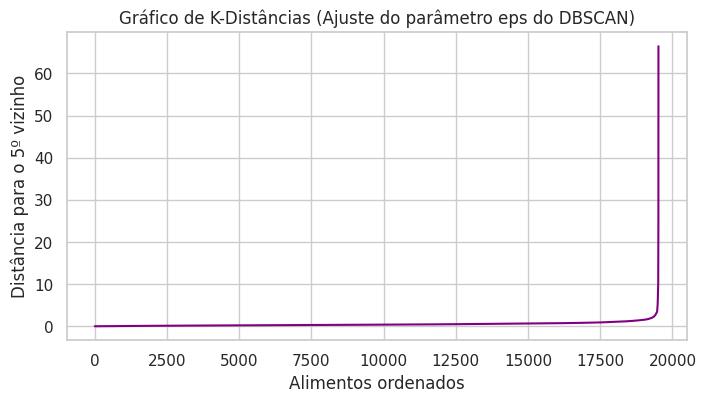

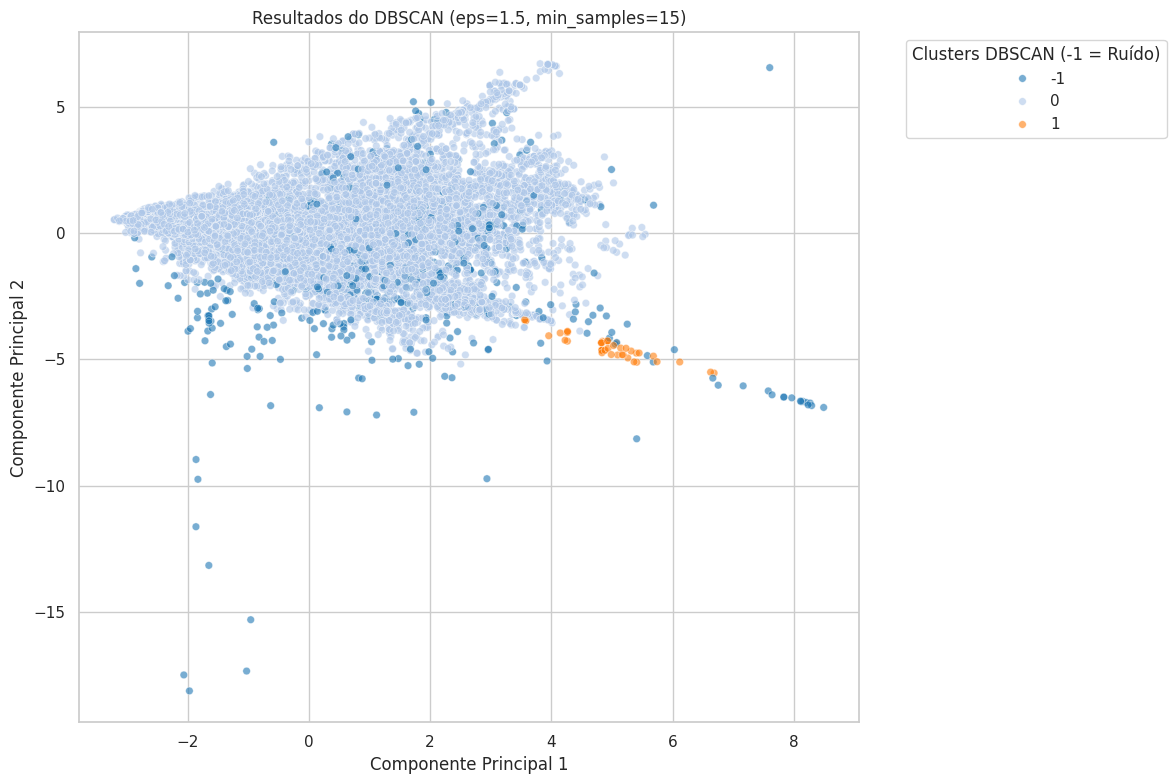


ANALISE
O DBSCAN encontrou 2 clusters válidos sozinhos.
Ele classificou 619 alimentos como RUÍDO (não se encaixam em lugar nenhum).

--- RUÍDO / OUTLIERS (Cluster -1) ---
pnns_groups_1
Fat and sauces          128
Cereals and potatoes    128
Sugary snacks           115
Name: count, dtype: int64

--- Cluster 0 ---
pnns_groups_1
Cereals and potatoes       5450
Sugary snacks              2968
Milk and dairy products    2711
Name: count, dtype: int64

--- Cluster 1 ---
pnns_groups_1
Fat and sauces             44
Milk and dairy products     3
Fruits and vegetables       1
Name: count, dtype: int64



In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

#calculamos a distancia de cada ponto ate o seu 5º vizinho mais próximo
vizinhos = NearestNeighbors(n_neighbors=5)
vizinhos_fit = vizinhos.fit(X_escalado)
distancias, indices = vizinhos_fit.kneighbors(X_escalado)

#ordenamos as distancias, menor pro maior
distancias = np.sort(distancias[:, 4], axis=0)

plt.figure(figsize=(8, 4))
plt.plot(distancias, color='purple')
plt.title('Gráfico de K-Distâncias (Ajuste do parâmetro eps do DBSCAN)')
plt.xlabel('Alimentos ordenados')
plt.ylabel('Distância para o 5º vizinho')
plt.grid(True)
plt.show()

# eps = raio de tolerancia
# min_samples = minimo de elementos para formar cluster
dbscan_oficial = DBSCAN(eps=1.5, min_samples=15)
grupos_dbscan = dbscan_oficial.fit_predict(X_escalado)

#salvando resultados
df_pca['Cluster_DBSCAN'] = grupos_dbscan
df_limpo['Cluster_DBSCAN'] = grupos_dbscan

#grafico
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x='Componente 1',
    y='Componente 2',
    hue='Cluster_DBSCAN',
    palette='tab20',
    data=df_pca,
    alpha=0.6,
    s=30
)

plt.title('Resultados do DBSCAN (eps=1.5, min_samples=15)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(title='Clusters DBSCAN (-1 = Ruído)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#analise
print("\nANALISE")
labels_unicas = np.unique(grupos_dbscan)
n_clusters = len(labels_unicas) - (1 if -1 in labels_unicas else 0)
n_ruido = list(grupos_dbscan).count(-1)

print(f"O DBSCAN encontrou {n_clusters} clusters válidos sozinhos.")
print(f"Ele classificou {n_ruido} alimentos como RUÍDO (não se encaixam em lugar nenhum).\n")

for cluster in labels_unicas:
    if cluster == -1:
        titulo = "RUÍDO / OUTLIERS (Cluster -1)"
    else:
        titulo = f"Cluster {cluster}"

    print(f"--- {titulo} ---")
    alimentos_do_cluster = df_limpo[df_limpo['Cluster_DBSCAN'] == cluster]['pnns_groups_1']
    print(alimentos_do_cluster.value_counts().head(3))
    print("")

Agrupamento Hierarquico

Escolhemos o Agrupamento Hierarquico pois ele revela a estrutura de relacoes entre os alimentos atraves de um dendrograma, permitindo visualizar a hierarquia e granularidade dos subgrupos existentes

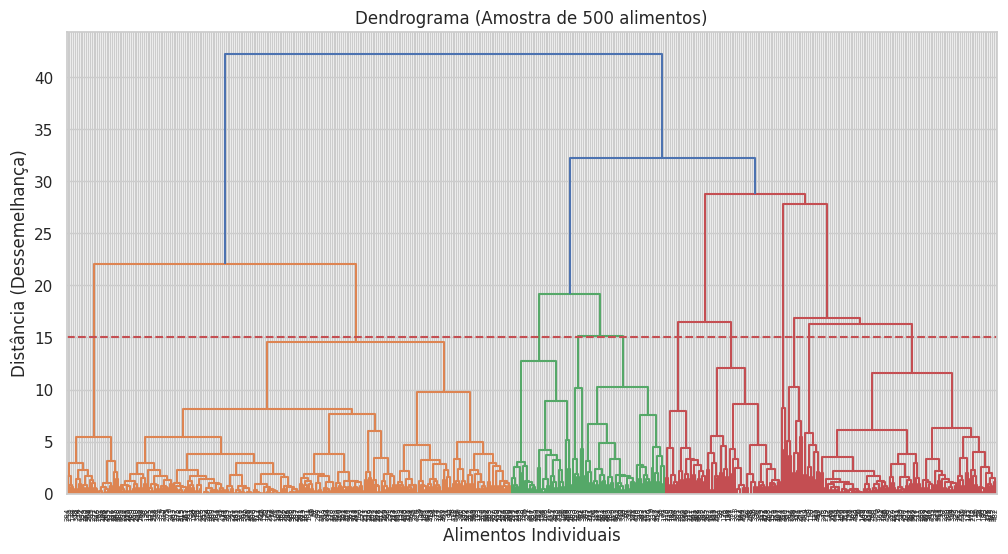


Aplicando Agrupamento Hierárquico na base inteira...


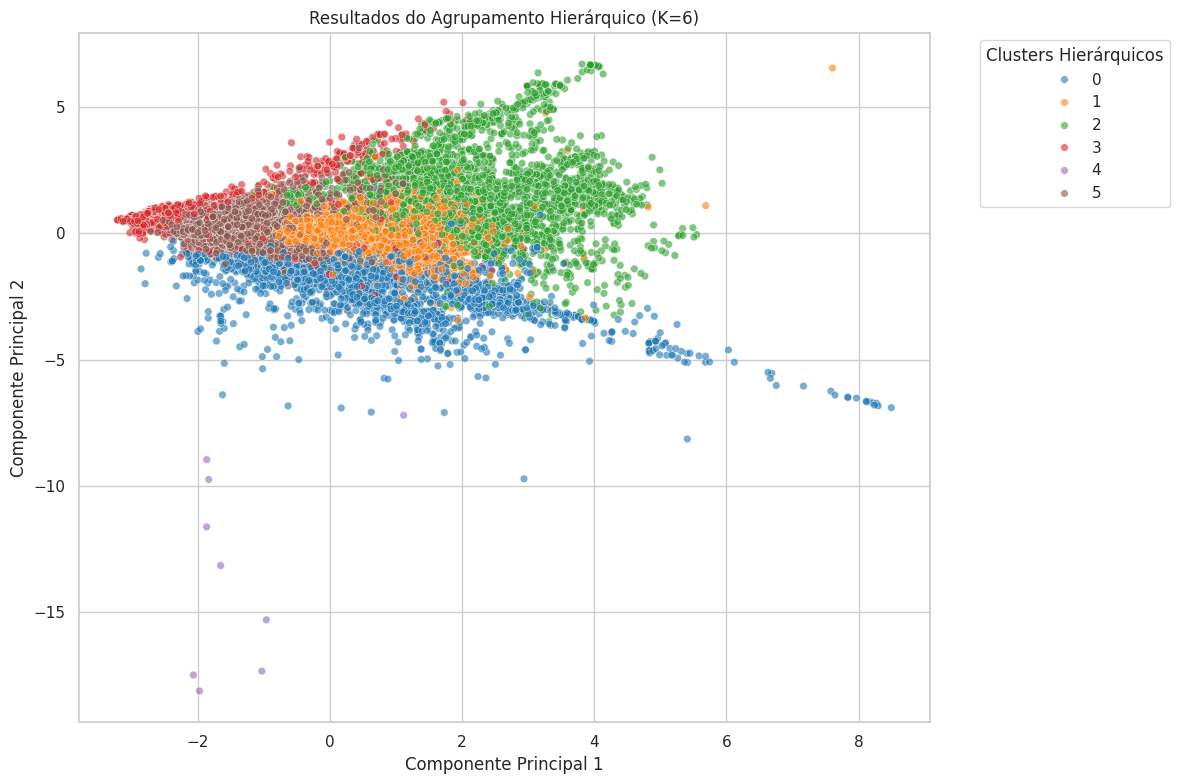


ANALISE

--- Cluster 0 ---
pnns_groups_1
Fish Meat Eggs             1108
Fat and sauces              628
Milk and dairy products     550
Name: count, dtype: int64

--- Cluster 1 ---
pnns_groups_1
Cereals and potatoes    3861
Salty snacks             537
Sugary snacks            463
Name: count, dtype: int64

--- Cluster 2 ---
pnns_groups_1
Sugary snacks            2128
Cereals and potatoes      629
Fruits and vegetables      89
Name: count, dtype: int64

--- Cluster 3 ---
pnns_groups_1
Fruits and vegetables    564
Fat and sauces           276
Beverages                166
Name: count, dtype: int64

--- Cluster 4 ---
pnns_groups_1
Beverages         3
Fat and sauces    1
Salty snacks      1
Name: count, dtype: int64

--- Cluster 5 ---
pnns_groups_1
Milk and dairy products    2100
Composite foods            1026
Beverages                   985
Name: count, dtype: int64


In [ ]:
from sklearn.cluster import AgglomerativeClustering
import scipy.cluster.hierarchy as shc
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

#gerando dendograma
#vamos extrair uma amostra aleatoria de apenas 500 alimentos para visualizar a estrutura
np.random.seed(42)
indices_amostra = np.random.choice(X_escalado.shape[0], size=500, replace=False)
amostra_X = X_escalado[indices_amostra]

plt.figure(figsize=(12, 6))
plt.title("Dendrograma (Amostra de 500 alimentos)")
# O método 'ward' minimiza a variancia dentro dos clusters que estao sendo unidos
dend = shc.dendrogram(shc.linkage(amostra_X, method='ward'))
plt.xlabel("Alimentos Individuais")
plt.ylabel("Distância (Dessemelhança)")
plt.axhline(y=15, color='r', linestyle='--')
plt.show()

# Vamos usar K=6 para podermos comparar diretamente com os resultados do K-Means
print("\nAplicando Agrupamento Hierárquico na base inteira...")
hierarquico = AgglomerativeClustering(n_clusters=6, linkage='ward')
grupos_hierarquicos = hierarquico.fit_predict(X_escalado)

#salvando
df_pca['Cluster_Hierarquico'] = grupos_hierarquicos
df_limpo['Cluster_Hierarquico'] = grupos_hierarquicos

#grafico
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x='Componente 1',
    y='Componente 2',
    hue='Cluster_Hierarquico',
    palette='tab10',
    data=df_pca,
    alpha=0.6,
    s=30
)

plt.title('Resultados do Agrupamento Hierárquico (K=6)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(title='Clusters Hierárquicos', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#analise
print("\nANALISE")
for cluster in range(6):
    print(f"\n--- Cluster {cluster} ---")
    alimentos_do_cluster = df_limpo[df_limpo['Cluster_Hierarquico'] == cluster]['pnns_groups_1']
    print(alimentos_do_cluster.value_counts().head(3))

Comparacao e resultados

In [ ]:
# ==========================================
# 8. COMPARAÇÃO E AVALIAÇÃO DE DESEMPENHO
# ==========================================
from sklearn.metrics import silhouette_score, adjusted_rand_score
import pandas as pd

print("Calculando as métricas matemáticas (isso pode levar alguns segundos)...\n")

# 1. Calculando o Silhouette Score (Qualidade Geométrica)
sil_kmeans = silhouette_score(X_escalado, grupos_kmeans)
sil_dbscan = silhouette_score(X_escalado, grupos_dbscan)
sil_hierarquico = silhouette_score(X_escalado, grupos_hierarquicos)

# 2. Calculando o Adjusted Rand Index (Similaridade com as Categorias Reais)
ari_kmeans = adjusted_rand_score(y_categorias, grupos_kmeans)
ari_dbscan = adjusted_rand_score(y_categorias, grupos_dbscan)
ari_hierarquico = adjusted_rand_score(y_categorias, grupos_hierarquicos)

# 3. Consolidando os resultados em uma tabela
tabela_comparativa = pd.DataFrame({
    'Algoritmo': ['K-Means (K=6)', 'DBSCAN', 'Hierárquico (K=6)'],
    'Silhouette Score (Coesão)': [sil_kmeans, sil_dbscan, sil_hierarquico],
    'ARI (Semelhança c/ Realidade)': [ari_kmeans, ari_dbscan, ari_hierarquico]
})

print("TABELA DE COMPARAÇÃO DOS MODELOS")
display(tabela_comparativa.round(4))

Calculando as métricas matemáticas (isso pode levar alguns segundos)...

TABELA DE COMPARAÇÃO DOS MODELOS


,Algoritmo,Silhouette Score (Coesão),ARI (Semelhança c/ Realidade)
0,K-Means (K=6),0.2831,0.2399
1,DBSCAN,0.4974,0.0044
2,Hierárquico (K=6),0.2376,0.2713
